# Week 02 - Fourier Transform Pairs

**Student:** NIKUL  
**Semester:** WS-26/27  
**Course:** CONTACTLESS SENSORS

This notebook follows the professor's Gaussian FFT example, using NumPy arrays, `np.fft.fftfreq`, shifted FFT plots, and Matplotlib. Time is in seconds and frequency is in hertz.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

assert sys.version_info >= (3, 14), "Use Python 3.14 or newer."

plt.style.use("_mpl-gallery")

STUDENT_ID = "NIKUL - WS-26/27 - CONTACTLESS SENSORS"


def add_student_id(fig):
    fig.text(0.99, 0.012, STUDENT_ID, ha="right", va="bottom", color="0.55", fontsize=8)


## 1. A single normalized rectangle

The function `r_W(x)` is centered at zero, has width `W`, height `1/W`, and is zero outside its width. Its area is one. Integrating a constant over a finite interval gives a sine divided by frequency, so its Fourier transform is the sinc function `np.sinc(W * f)`. NumPy's sinc is `sin(pi*z)/(pi*z)`. The first zero is at `|f| = 1/W`: a wider rectangle has a narrower transform, while a narrower rectangle has a broader transform.

In [2]:
def r_W(x, W):
    """Return a unit-area rectangle of width W, centered at zero."""
    if W <= 0:
        raise ValueError("W must be positive.")
    return np.where(np.abs(x) < W / 2, 1 / W, 0.0)


sample_count = 8192
dx = 0.005
x = (np.arange(sample_count) - (sample_count - 1) / 2) * dx
frequency = np.fft.fftshift(np.fft.fftfreq(sample_count, d=dx))
widths = [0.5, 1.0, 2.0]

print(f"Sampling interval dx = {dx:g} s")
print(f"Frequency-bin spacing = {frequency[1] - frequency[0]:.6f} Hz")
print(f"Nyquist frequency = {1 / (2 * dx):g} Hz")

Sampling interval dx = 0.005 s
Frequency-bin spacing = 0.024414 Hz
Nyquist frequency = 100 Hz


The time samples are centered between grid points so the rectangle edges are not sampled ambiguously. Multiplying the FFT by `dx` makes its sum approximate the continuous Fourier integral; at zero frequency, this equals the rectangle's sampled area. `np.fft.fftfreq` builds the frequency axis from the correct sampling interval, and `fftshift` moves zero frequency to the center. The phase correction accounts for the half-sample offset of this centered grid.

W=0.5 s: height=2 1/s, area=1.000000, FFT at f=0=1.000000, max FFT/sinc difference=0.000184275, first zero=2.0020 Hz
W=1 s: height=1 1/s, area=1.000000, FFT at f=0=1.000000, max FFT/sinc difference=4.59895e-05, first zero=1.0010 Hz
W=2 s: height=0.5 1/s, area=1.000000, FFT at f=0=1.000000, max FFT/sinc difference=1.1492e-05, first zero=0.4883 Hz


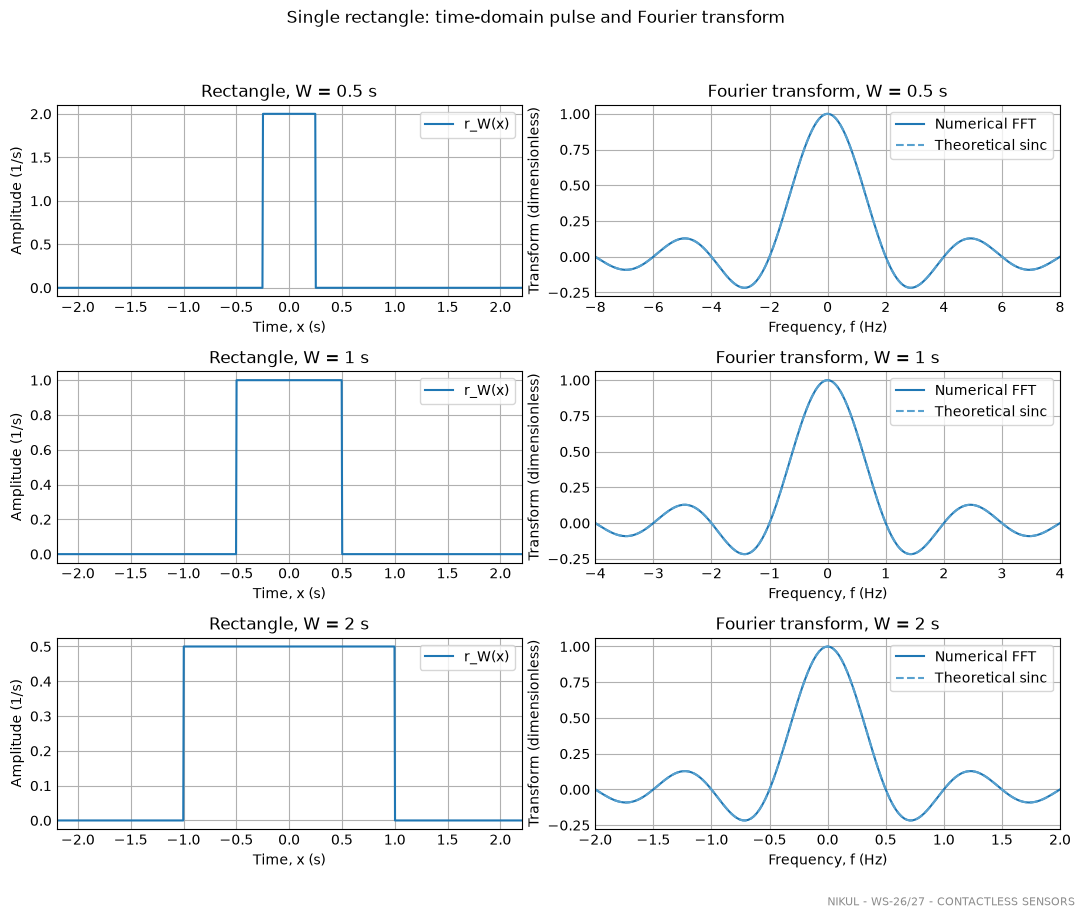

In [3]:
fig, axes = plt.subplots(len(widths), 2, figsize=(11, 9))
first_zeros = []

for row, W in enumerate(widths):
    rectangle = r_W(x, W)
    transform = dx * np.fft.fftshift(np.fft.fft(np.fft.ifftshift(rectangle)))
    transform *= np.exp(-2j * np.pi * frequency * dx / 2)
    theoretical_transform = np.sinc(W * frequency)

    time_axis = axes[row, 0]
    time_axis.plot(x, rectangle, label="r_W(x)")
    time_axis.set_xlim(-2.2, 2.2)
    time_axis.set_title(f"Rectangle, W = {W:g} s")
    time_axis.set_xlabel("Time, x (s)")
    time_axis.set_ylabel("Amplitude (1/s)")
    time_axis.legend()

    frequency_axis = axes[row, 1]
    frequency_axis.plot(frequency, transform.real, label="Numerical FFT")
    frequency_axis.plot(frequency, theoretical_transform, "--", label="Theoretical sinc")
    frequency_axis.set_xlim(-4 / W, 4 / W)
    frequency_axis.set_title(f"Fourier transform, W = {W:g} s")
    frequency_axis.set_xlabel("Frequency, f (Hz)")
    frequency_axis.set_ylabel("Transform (dimensionless)")
    frequency_axis.legend()

    area = np.sum(rectangle) * dx
    zero_index = np.argmin(np.abs(frequency))
    zero_frequency_value = transform[zero_index].real
    comparison_band = np.abs(frequency) <= 4 / W
    max_difference = np.max(
        np.abs(transform.real[comparison_band] - theoretical_transform[comparison_band])
    )
    first_zero_band = (frequency >= 0.8 / W) & (frequency <= 1.2 / W)
    first_zero = frequency[first_zero_band][
        np.argmin(np.abs(transform.real[first_zero_band]))
    ]
    first_zeros.append(first_zero)

    assert np.count_nonzero(rectangle) == round(W / dx)
    assert np.isclose(rectangle.max(), 1 / W)
    assert np.isclose(area, 1.0, atol=1e-12)
    assert np.isclose(zero_frequency_value, area, atol=1e-12)
    assert max_difference < 0.01
    assert abs(first_zero - 1 / W) <= frequency[1] - frequency[0]

    print(
        f"W={W:g} s: height={rectangle.max():g} 1/s, area={area:.6f}, "
        f"FFT at f=0={zero_frequency_value:.6f}, "
        f"max FFT/sinc difference={max_difference:.6g}, "
        f"first zero={first_zero:.4f} Hz"
    )

assert first_zeros[0] > first_zeros[1] > first_zeros[2]
fig.suptitle("Single rectangle: time-domain pulse and Fourier transform", y=1.01)
add_student_id(fig)
fig.tight_layout(rect=(0, 0.04, 1, 0.98))
plt.show()

## 2. The professor's cosine-sign rectangle train

The required expression is `0.5 * (1 + np.sign(np.cos(2 * np.pi * u * x)))`. It repeats every `P = 1/u` seconds and has a 50% duty cycle. A periodic signal produces discrete peaks at integer multiples of its repetition frequency; these are its harmonics. The record below contains exactly ten periods, so the harmonics land on FFT bins. Using a whole number of periods avoids spectral leakage from cutting the record between cycles. The half-sample time grid avoids sampling the formula's isolated transition values, where `np.sign(0)` would give 0.5.

In [4]:
u = 0.5
period = 1 / u
period_count = 10
record_duration = period_count * period
sample_rate = 1024
train_sample_count = int(record_duration * sample_rate)
dt = 1 / sample_rate
x_train = (np.arange(train_sample_count) - train_sample_count / 2 + 0.5) * dt

rectangle_train = 0.5 * (1 + np.sign(np.cos(2 * np.pi * u * x_train)))
train_frequency = np.fft.fftshift(np.fft.fftfreq(train_sample_count, d=dt))
train_transform = np.fft.fftshift(np.fft.fft(rectangle_train)) / train_sample_count
frequency_step = train_frequency[1] - train_frequency[0]

assert np.isclose(record_duration / period, period_count)
assert set(np.unique(rectangle_train)) == {0.0, 1.0}
assert np.isclose(np.mean(rectangle_train), 0.5)
assert np.isclose(u / frequency_step, round(u / frequency_step))

print(f"u = {u:g} Hz; period = {period:g} s; periods in record = {period_count}")
print(f"Record duration = {record_duration:g} s; FFT-bin spacing = {frequency_step:g} Hz")
print(f"Harmonic spacing = {u:g} Hz; samples per period = {int(period * sample_rate)}")

u = 0.5 Hz; period = 2 s; periods in record = 10
Record duration = 20 s; FFT-bin spacing = 0.05 Hz
Harmonic spacing = 0.5 Hz; samples per period = 2048


The train FFT is divided by the number of samples, giving Fourier-series coefficients rather than an unscaled FFT. The peak spacing is the repetition frequency `u`. For this centered 50% duty-cycle train, the even nonzero harmonic orders are zero.

Largest coefficient difference from theory = 8.74e-07


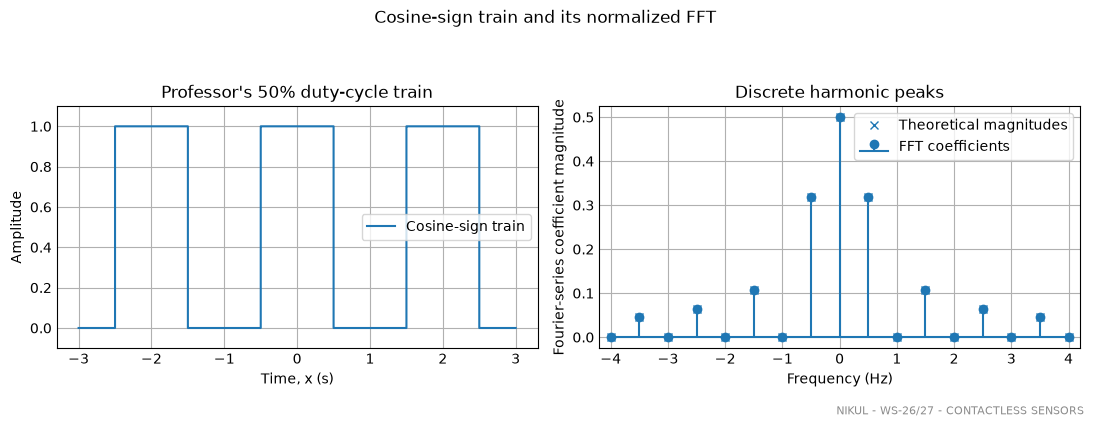

In [5]:
harmonic_order = np.arange(-8, 9)
harmonic_frequency = harmonic_order * u
harmonic_bins = np.rint((harmonic_frequency - train_frequency[0]) / frequency_step).astype(int)
assert np.allclose(train_frequency[harmonic_bins], harmonic_frequency)

duty_cycle = 0.5
expected_harmonic_magnitude = duty_cycle * np.abs(np.sinc(harmonic_order * duty_cycle))
measured_harmonic_magnitude = np.abs(train_transform[harmonic_bins])
coefficient_error = np.max(
    np.abs(measured_harmonic_magnitude - expected_harmonic_magnitude)
)
assert coefficient_error < 0.002
assert np.isclose(measured_harmonic_magnitude[harmonic_order == 0][0], 0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
visible_time = (x_train >= -3 * period / 2) & (x_train < 3 * period / 2)
axes[0].plot(x_train[visible_time], rectangle_train[visible_time], drawstyle="steps-post", label="Cosine-sign train")
axes[0].set_title("Professor's 50% duty-cycle train")
axes[0].set_xlabel("Time, x (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_ylim(-0.1, 1.1)
axes[0].legend()

axes[1].stem(harmonic_frequency, measured_harmonic_magnitude, label="FFT coefficients")
axes[1].plot(harmonic_frequency, expected_harmonic_magnitude, "x", label="Theoretical magnitudes")
axes[1].set_xlim(-4.2, 4.2)
axes[1].set_title("Discrete harmonic peaks")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Fourier-series coefficient magnitude")
axes[1].legend()

print(f"Largest coefficient difference from theory = {coefficient_error:.3g}")
fig.suptitle("Cosine-sign train and its normalized FFT", y=1.03)
add_student_id(fig)
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.show()

## 3. Changing pulse width in a periodic train

The supplied cosine-sign expression has no adjustable `W`; it fixes the duty cycle at 50%. This experiment uses a modified periodic rectangle: each time sample is wrapped into one period and the pulse is one within `W/2` of its center. The period stays fixed as `W` changes, so the duty cycle is `W/period`. The DC coefficient equals the duty cycle. Wider pulses narrow the sinc-shaped harmonic envelope; narrower pulses broaden it. Harmonic spacing stays the same because the period is unchanged.

W=0.5 s: duty cycle=0.25, DC coefficient=0.250000, largest coefficient difference=1.25e-06
W=1 s: duty cycle=0.50, DC coefficient=0.500000, largest coefficient difference=1.37e-06
W=1.5 s: duty cycle=0.75, DC coefficient=0.750000, largest coefficient difference=1.25e-06


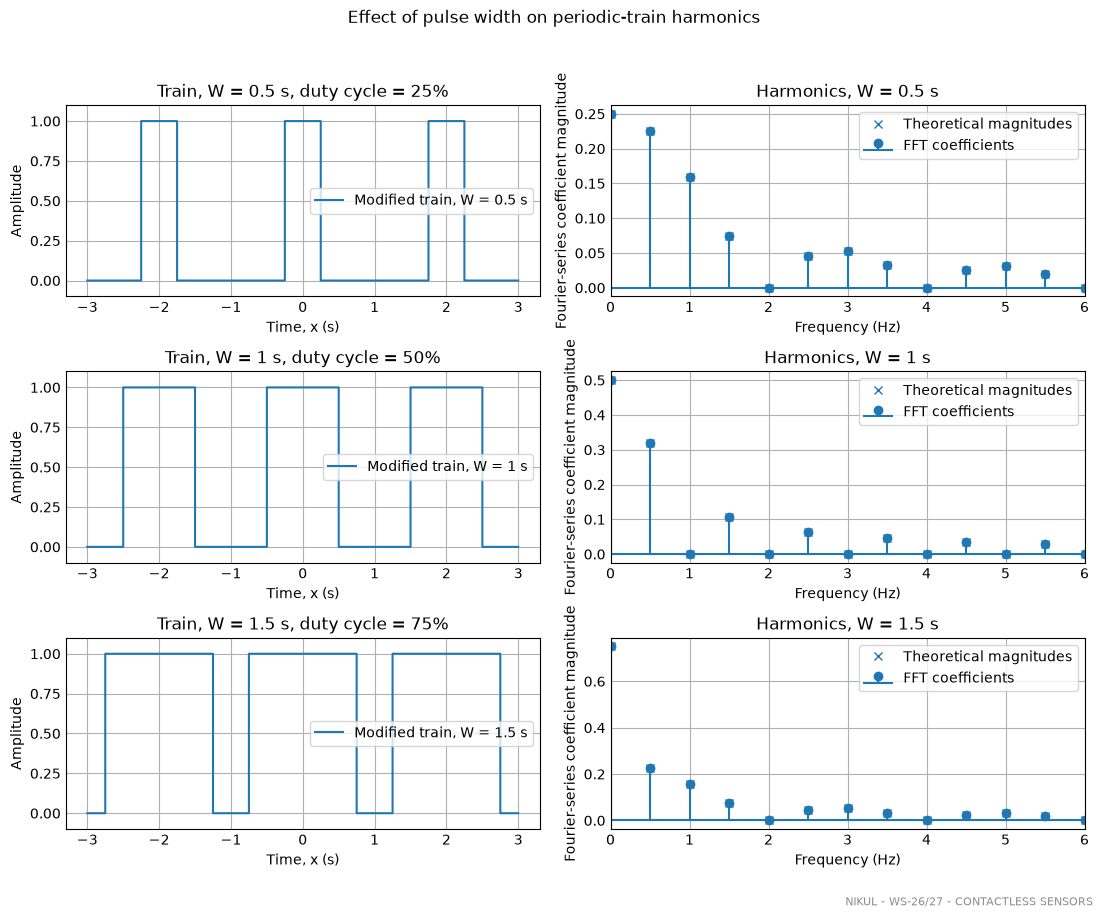

In [6]:
train_widths = [0.5, 1.0, 1.5]
positive_harmonic_order = np.arange(0, 13)
positive_harmonic_frequency = positive_harmonic_order * u
positive_harmonic_bins = np.rint(
    (positive_harmonic_frequency - train_frequency[0]) / frequency_step
).astype(int)
assert np.allclose(train_frequency[positive_harmonic_bins], positive_harmonic_frequency)

fig, axes = plt.subplots(len(train_widths), 2, figsize=(11, 9))

for row, W in enumerate(train_widths):
    phase_in_period = (x_train + period / 2) % period - period / 2
    width_train = (np.abs(phase_in_period) < W / 2).astype(float)
    width_transform = np.fft.fftshift(np.fft.fft(width_train)) / train_sample_count
    duty_cycle = W / period
    expected_magnitude = duty_cycle * np.abs(
        np.sinc(positive_harmonic_order * duty_cycle)
    )
    measured_magnitude = np.abs(width_transform[positive_harmonic_bins])
    width_error = np.max(np.abs(measured_magnitude - expected_magnitude))

    axes[row, 0].plot(
        x_train[visible_time],
        width_train[visible_time],
        drawstyle="steps-post",
        label=f"Modified train, W = {W:g} s",
    )
    axes[row, 0].set_title(f"Train, W = {W:g} s, duty cycle = {duty_cycle:.0%}")
    axes[row, 0].set_xlabel("Time, x (s)")
    axes[row, 0].set_ylabel("Amplitude")
    axes[row, 0].set_ylim(-0.1, 1.1)
    axes[row, 0].legend()

    axes[row, 1].stem(
        positive_harmonic_frequency,
        measured_magnitude,
        label="FFT coefficients",
    )
    axes[row, 1].plot(
        positive_harmonic_frequency,
        expected_magnitude,
        "x",
        label="Theoretical magnitudes",
    )
    axes[row, 1].set_xlim(0, 6)
    axes[row, 1].set_title(f"Harmonics, W = {W:g} s")
    axes[row, 1].set_xlabel("Frequency (Hz)")
    axes[row, 1].set_ylabel("Fourier-series coefficient magnitude")
    axes[row, 1].legend()

    assert np.isclose(np.mean(width_train), duty_cycle)
    assert width_error < 0.002
    print(
        f"W={W:g} s: duty cycle={duty_cycle:.2f}, "
        f"DC coefficient={measured_magnitude[0]:.6f}, "
        f"largest coefficient difference={width_error:.3g}"
    )

fig.suptitle("Effect of pulse width on periodic-train harmonics", y=1.01)
add_student_id(fig)
fig.tight_layout(rect=(0, 0.04, 1, 0.98))
plt.show()

## Summary

The single unit-area rectangle has a sinc transform whose width varies inversely with `W`. A periodic train has discrete harmonic peaks. Its pulse width controls duty cycle and the harmonic envelope, but the professor's given formula remains fixed at 50% duty cycle. The assertions check rectangle height and area, the zero-frequency transform value, harmonic-bin alignment, and agreement with theoretical values.